For project 1, the SST-2 (Stanford Sentiment Treebank) dataset was chosen. This dataset contains a text and its corresponding label. Where the label describes this text as positive, neutral or negative.

In [1]:
import numpy as np
import os
print(os.getcwd()) # make sure if this ends in /Project1 go one up
os.chdir("..")

/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1


In [2]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/sst2")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 872
    })
    test: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 1821
    })
})


The following loads the trained tokeniser that was trained in the tutorial on the AG corpus, a collection of more than 1 million news articles.

In [3]:
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_file(
    f"Project1/results/BPE_tokenizer_vs_1000_mf_2.json"
)

output = tokenizer.encode(dataset['train']['sentence'][0])

print(output.tokens)

['▁h', 'ide', '▁new', '▁sec', 're', 't', 'ions', '▁from', '▁the', '▁p', 'ar', 'ent', 'al', '▁un', 'its', '▁']


The following code sets up the cross validations split

In [4]:
import Project1.experiment as experiment

my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["sentence"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

Below the token indicator feature representation space is copied from tutorial 1.

In [5]:
from tokenizers import Tokenizer

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

Training the log linear model with an indicator encoder.

In [ ]:
from collections import OrderedDict
my_classifiers = OrderedDict()

stanfordnlpsst2_outcome_space = clslib.NamedClasses([ 'negative', 'positive'])
token_indicator_encoder = TokenIndicator(tokenizer)

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"Project1/results/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/taravd/miniconda3/envs/nlp1/lib/python

Results

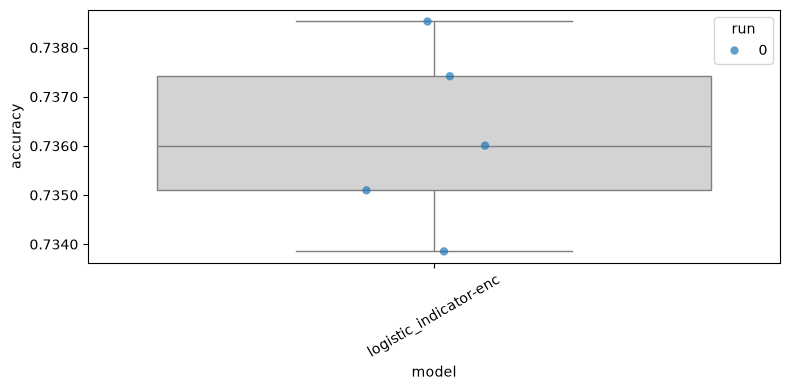

In [9]:
import Project1.analysis as analysis
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [ ]:
import Project1.loglin as loglin
from sklearn.metrics import classification_report

def report_all_folds(seed=0, split="validation", num_folds=num_folds):
    X = np.vstack([token_indicator_encoder(s) for s in dataset[split]["sentence"]])  # encode once
    y_true = dataset[split]["label"]

    for fold in range(num_folds):
        path = f"Project1/results/logistic_indicator-enc/seed-{seed}/fold-{fold}/model"
        model = loglin.load(path)
        y_pred = model.predict(X)

        print(f"=== seed {seed}, fold {fold} ===")
        print(classification_report(y_true, y_pred,
                                    target_names=stanfordnlpsst2_outcome_space.names))

report_all_folds()

=== seed 0, fold 0 ===
              precision    recall  f1-score   support

    negative       0.71      0.70      0.70       428
    positive       0.71      0.72      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872

=== seed 0, fold 1 ===
              precision    recall  f1-score   support

    negative       0.71      0.69      0.70       428
    positive       0.71      0.73      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872

=== seed 0, fold 2 ===
              precision    recall  f1-score   support

    negative       0.71      0.71      0.71       428
    positive       0.72      0.72      0.72       444

    accuracy                           0.72       872
   macro avg       0.72      0.72      0.72       872
weigh

In [23]:
import Project1.loglin as loglin
from sklearn.metrics import classification_report

path = 'Project1/results/logistic_indicator-enc/seed-0/fold-3/model'
model = loglin.load(path)

X = dataset['validation']['sentence']
X_tokanised = np.vstack([token_indicator_encoder(s) for s in X]) 
Y_pred = model.predict(X_tokanised)

print(classification_report(dataset["validation"]["label"], Y_pred, target_names=stanfordnlpsst2_outcome_space.names))

              precision    recall  f1-score   support

    negative       0.71      0.70      0.70       428
    positive       0.71      0.73      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872



???

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=nan P(Tie)=nan P(B wins)=nan Effect Size=nan


/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2162: RuntimeWarning: divide by zero encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)
/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1/analysis.py:117: RuntimeWarning: invalid value encountered in scalar divide
  return self.mean_diff / self.std
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2337: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2338: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


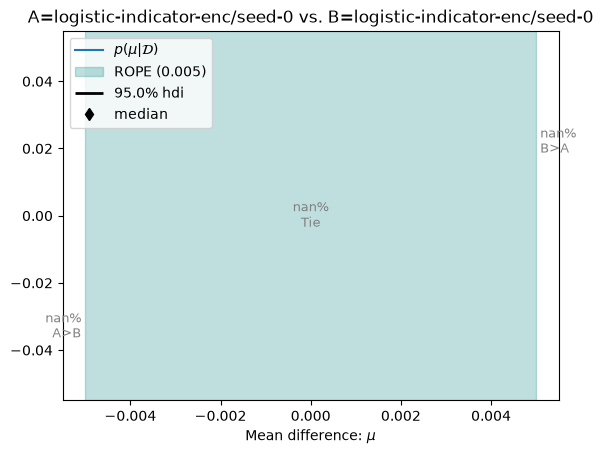

In [ ]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    names=["logistic-indicator-enc/seed-0", "logistic-indicator-enc/seed-0"]
)
p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005)  # if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)